## Inspect and Load the DATA

In [1]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("mabahboh/sitr-arabic-pii")

# Inspect the available splits
print(ds)

# Inspect the columns and one sample
print(ds["train"].column_names)
print(ds["train"][0])

# Convert training data to DataFrame
df = ds["train"].to_pandas()

print(df.shape)
display(df.head())
df.info()

c:\Users\lamaa\OneDrive\سطح المكتب\confidentiality-detector\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['text', 'entities', 'type', 'secret_text'],
        num_rows: 14288
    })
    validation: Dataset({
        features: ['text', 'entities', 'type', 'secret_text'],
        num_rows: 1818
    })
    test: Dataset({
        features: ['text', 'entities', 'type', 'secret_text'],
        num_rows: 1793
    })
})
['text', 'entities', 'type', 'secret_text']
{'text': 'هل مكن اختصار هذا العقد أحتاج نسخة مختصرة تمرر للقسم المالي\n\nعقد تأجير مركبة\nالمؤجر شركة تأجير السيارات المتحدة\nالمستأجر مؤسسة نقل الرمال\nتاريخ العقد 2024/02/01\n\nالبند 1 المركبة محل التعاقد\nالنوع نقل خفيف\nرقم اللوحة ه س ص 900\nرقم الهيكل: مسجل في اوراق المركبة الاصلية\n\nالبند 2: مدة الايجار\nتبدا من 2024/02/01 وتنتهي في 2024/07/31\nتجديد تلقائي لمدة سنة واحدة ان لم يخطر احد الطرفين الاخر قبل 30 يوماً.\n\nالبند 3: القيمة الايجارية\n10,500 ريال شهرياً تدفع في اول خمسة ايام من كل شهر ميلادي.\n\nالبند 4: الضمان\nلا يوجد ضمان بنكي. مقابل الايجار: شيك بقيمة 89,300 ريال مح

,text,entities,type,secret_text
0,هل مكن اختصار هذا العقد أحتاج نسخة مختصرة تمرر...,"[{'start': 216, 'end': 225, 'label': 'vehicle_...",vehicle_plate,هل مكن اختصار هذا العقد أحتاج نسخة مختصرة تمرر...
1,اسمع الموظف بيقول لى ان الوثيقه P684173823 مش ...,"[{'start': 32, 'end': 42, 'label': 'insurance_...",insurance_policy,اسمع الموظف بيقول لى ان الوثيقه {insurance_pol...
2,Simplify the following text for me.\n\nعرض سعر...,[],negative,Simplify the following text for me.\n\nعرض سعر...
3,طالبه الجامعة مستعجلة والملزمة ناقصة من كراتين...,"[{'start': 47, 'end': 52, 'label': 'postal_cod...",postal_code,طالبه الجامعة مستعجلة والملزمة ناقصة من كراتين...
4,متي يتعدل الاسم الإنجليزي في الجواز خلصت إجراء...,"[{'start': 58, 'end': 67, 'label': 'private_ph...",private_phone,متي يتعدل الاسم الإنجليزي في الجواز خلصت إجراء...


<class 'pandas.DataFrame'>
RangeIndex: 14288 entries, 0 to 14287
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   text         14288 non-null  str   
 1   entities     14288 non-null  object
 2   type         14288 non-null  str   
 3   secret_text  14288 non-null  str   
dtypes: object(1), str(3)
memory usage: 15.4+ MB


## Text Length Analysis

,char_count,word_count
count,14288.000000,14288.000000
mean,329.136758,53.278275
std,279.330413,42.423531
min,13.000000,2.000000
25%,109.000000,19.000000
50%,237.000000,42.000000
75%,493.000000,79.000000
max,2154.000000,359.000000


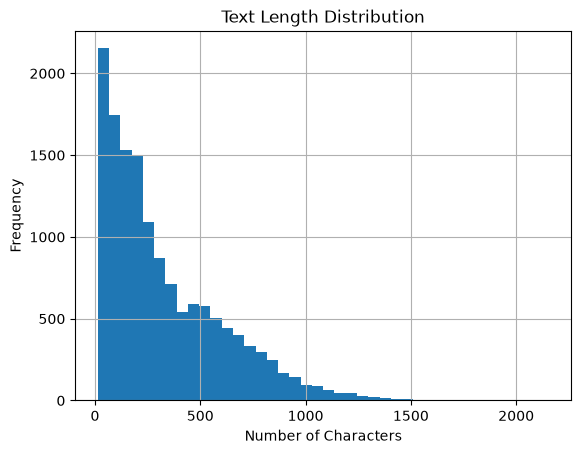

In [2]:
import matplotlib.pyplot as plt

df["char_count"] = df["text"].str.len()

df["word_count"] = df["text"].str.split().str.len()

display(df[["char_count", "word_count"]].describe())

df["char_count"].hist(bins=40)

plt.title("Text Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

# Short Text Analysis

In [3]:
#Define short texts as fewer than 50 characters

short_texts = df[df["char_count"] < 50]

print("Number of short texts:", len(short_texts))

print("Percentage of short texts:", round(len(short_texts) / len(df) * 100, 2), "%")

#Inspect the 15 shortest texts
display(df.nsmallest(15, "char_count")[["text", "char_count","word_count"]])

Number of short texts: 1381
Percentage of short texts: 9.67 %


,text,char_count,word_count
9879,طيب ما تقصرون,13,3
10866,رمز الأمان ٦٦٨,14,3
10867,رمز الأمان 826,14,3
10868,رمز الأمان 584,14,3
3661,ليش ما يردون ابد,16,4
10869,رمز الامان763 ؟؟,16,3
8792,وش أسوي 566255068؟,18,3
8434,التأمين ما غطى ديان,19,4
13941,10-08-1988 — صح ولا,19,4
13942,08/05/1394 — صح ولا,19,4


In [4]:
short_texts = short_texts.copy()

short_texts["entity_count"] = short_texts["entities"].apply(len)

display(short_texts["entity_count"].value_counts().sort_index())

entity_count
0     167
1    1186
2      27
3       1
Name: count, dtype: int64

In [5]:
display(
    short_texts[short_texts["entity_count"] == 0][
        ["text", "char_count"]
    ].head(10)
)

,text,char_count
43,مستحيل ادفعها، المخالفة مو وقتي. ؟؟,35
150,وش الحل؟ ابني مسجل في مدرستين,29
192,كلموني على الجوال ولا في فايدة,30
244,وش اسم الخدمه هذي؟ حواله سريعه؟ بانتظار ردكم,45
532,ليششش نقل الكفالة واقف ما في رد من أسبوعين شكراً,48
538,السجل التجاري واقع والسبب مش عارفه بانتظار ردكم,47
599,ابشررررر يطلب شي وما فهمت,25
714,تنبيهي معروف بس صرفوه لي,24
886,الصفحه ترسل لكن محد يرد، اريد بس افتح حساب.,43
910,أعد صياغة هذه الرسالة لتكون أكثر رسمية.,39


In [6]:
display(
    short_texts[short_texts["entity_count"] > 0][
        ["text", "char_count", "entity_count"]
    ].head(10)
)

,text,char_count,entity_count
29,الصك 327552685709 باسمي وأبي أأجر الوحدة,40,1
30,الصك 365777472144 باسي وأبي أأجر الوحدة,39,1
31,الصك 317991391395 باسمي وابييي ااجر الوحدة,43,1
32,الصك 372842123583 باسمي وأبي أأجر الوحده؟,42,1
33,الصك 348930607179 باسمي وأبي أأجر الوحدةةة...,45,1
42,ما عليك ورقمها 1484738784 ومسحت نص,34,1
45,28187504150 بس يبغاله تصحيح قبل لا ينتهي,40,1
54,أبي أضيف مرافق على الوثيقة P8228390705,38,1
55,أبي أضيف مرافق على الوثيقه INS9058380420؟,41,1
56,ابي اضيف مرافق على الوثيقة INS700880381,39,1


# Short Text Analysis - Findings 

Out of 14,288 training samples, 1,381 (9.67%) contain fewer than 50 characters.

Among these short texts:
- 167 samples have no annotated entities.
- 1,186 samples contain one entity. 
- 27 samples contain two entities.
- 1 sample contains three entities.

Manual inspection of the displayed examples suggests that short texts are often valid conversational messages or contain identifiable sensitive information.

Several examples also appear to follow repetitive templates, which may require further duplicate and near-duplicate analysis.

Decision: Retain short texts at this stage. No minimum-length filtering will be applied until further data-quality checks are completed.

## Number Of Entities In Text Analysis

count    14288.000000
mean         2.279115
std          3.111818
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         32.000000
Name: entity_count, dtype: float64
Texts with no entities: 2867


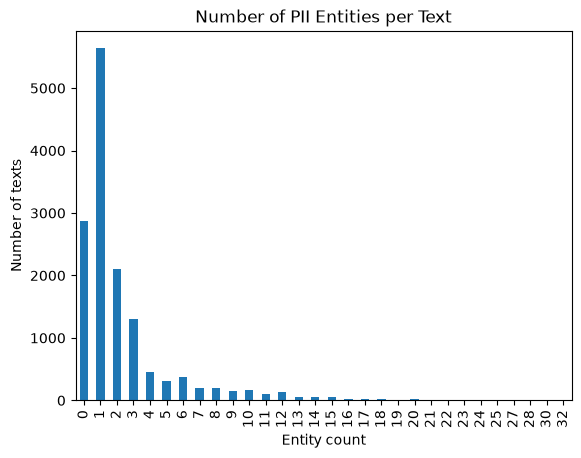

In [7]:
df["entity_count"] = df["entities"].apply(len)

print(df["entity_count"].describe())

print("Texts with no entities:", (df["entity_count"] == 0).sum())

df["entity_count"].value_counts().sort_index().plot(kind="bar")

plt.title("Number of PII Entities per Text")
plt.xlabel("Entity count")
plt.ylabel("Number of texts")
plt.show()

## PII Entity Count Distribution - Findings

The training dataset contains 14,288 text samples, with an average os 2.28 annotated PII entities per text.

The median is 1 entity, indicating that at least half of the samples contain one or fewer annotated entities. The distribution is right-skewed, with a maximum of 32 entities in a single text.

A total of 2,867 samples (20.07%) contain no annotated entities, while 11,421 samples (79.93%) contain at least one.

Key observations:
- Single-entity texts are the most frequent.
- Multi-entity texts are less common but important for evaluating complete PII detection.
- The dataset has an approximately 80/20 split between texts with and without annotated entities.
- Samples containing unusually high numbers of entities require further inspection.

In [8]:
# Inspect texts with the highest number of entities

pd.set_option("display.max_colwidth", None)

display(
    df.nlargest(5, "entity_count")[
        ["text", "char_count", "entity_count", "entities"]
    ]
)

,text,char_count,entity_count,entities
4550,ترجم هذه القائمه من السجلات إلى الإنجليزيه مع الحفاظ على التنسيق\n\nشركه الحرمين للمقاولات\nسجل الموظفين الوافدين - دفعه مارس 2024\n\nمم | الاسم | رقم الإقامه | تاريخ الميلاد | العنوان الوطني | رقم الجوال\n1 | محمد أحمد علي | 2435589755 | 1416/08/13 | 2461 طريق المدينة، حي المروج، الخرج 24535-6831 | 0563389219\n2 | راجيش كومار | 2094244577 | 01-04-1401 | 6357 شارع الستين، حي النرجس، الباحة 52082-0024 | 562840868\n3 | عبدالرحمن يوسف | 2690120536 | 17/12/1950 | 3877 شارع الستين، حي النرجس، الظهران 03955-5697 | 506021875\n4 | اسمي ابراهيممممم | 2041770476 | 13/02/1953 | 8542 شارع الخليج، حي الخزامى، جازان 01172-0298 | +966554102086\n5 | حسن مهدي | 2708374570 | 1956/03/28 | 7754 شارع الستين، حي قرطبة، الرياض 22476-8069 | 00966593632600\n6 | علييي رضا | 2104054586 | 03-01-1965 | 4557 شارع الأمير سلطان، حي الخزامى، مكه المكرمه 19234-7145 | +966538623951\n7 | فيصل اصر | 2230960540 | 1985/10/21 | 2783 شارع الأمير سلطان، حي قرطبة، جيزان 09591-7570 | +966505804569\n8 | طارققق زياد | 2445011204 | 2007-11-22 | 0662 طريق الملك عبدالله، حي الربيع، مكة المكرمة 01124-3069 | 0535822428\n\nملاحظه: جميع الموظفين المذكورين اعلاه لديهم اقاماتتتتت ساريه حتى نهايه عام 2024.\n\nتوقيع المسؤول:\nسعود القحطاني\nمدير الموارد البشريه ومشكورين,1216,32,"[{'start': 220, 'end': 230, 'label': 'iqama', 'text': '2435589755'}, {'start': 233, 'end': 243, 'label': 'private_date', 'text': '1416/08/13'}, {'start': 246, 'end': 292, 'label': 'national_address', 'text': '2461 طريق المدينة، حي المروج، الخرج 24535-6831'}, {'start': 295, 'end': 305, 'label': 'private_phone', 'text': '0563389219'}, {'start': 324, 'end': 334, 'label': 'iqama', 'text': '2094244577'}, {'start': 337, 'end': 347, 'label': 'private_date', 'text': '01-04-1401'}, {'start': 350, 'end': 396, 'label': 'national_address', 'text': '6357 شارع الستين، حي النرجس، الباحة 52082-0024'}, {'start': 399, 'end': 408, 'label': 'private_phone', 'text': '562840868'}, {'start': 431, 'end': 441, 'label': 'iqama', 'text': '2690120536'}, {'start': 444, 'end': 454, 'label': 'private_date', 'text': '17/12/1950'}, {'start': 457, 'end': 504, 'label': 'national_address', 'text': '3877 شارع الستين، حي النرجس، الظهران 03955-5697'}, {'start': 507, 'end': 516, 'label': 'private_phone', 'text': '506021875'}, {'start': 541, 'end': 551, 'label': 'iqama', 'text': '2041770476'}, {'start': 554, 'end': 564, 'label': 'private_date', 'text': '13/02/1953'}, {'start': 567, 'end': 613, 'label': 'national_address', 'text': '8542 شارع الخليج، حي الخزامى، جازان 01172-0298'}, {'start': 616, 'end': 629, 'label': 'private_phone', 'text': '+966554102086'}, {'start': 645, 'end': 655, 'label': 'iqama', 'text': '2708374570'}, {'start': 658, 'end': 668, 'label': 'private_date', 'text': '1956/03/28'}, {'start': 671, 'end': 716, 'label': 'national_address', 'text': '7754 شارع الستين، حي قرطبة، الرياض 22476-8069'}, {'start': 719, 'end': 733, 'label': 'private_phone', 'text': '00966593632600'}, {'start': 750, 'end': 760, 'label': 'iqama', 'text': '2104054586'}, {'start': 763, 'end': 773, 'label': 'private_date', 'text': '03-01-1965'}, {'start': 776, 'end': 834, 'label': 'national_address', 'text': '4557 شارع الأمير سلطان، حي الخزامى، مكه المكرمه 19234-7145'}, {'start': 837, 'end': 850, 'label': 'private_phone', 'text': '+966538623951'}, {'start': 866, 'end': 876, 'label': 'iqama', 'text': '2230960540'}, {'start': 879, 'end': 889, 'label': 'private_date', 'text': '1985/10/21'}, {'start': 892, 'end': 942, 'label': 'national_address', 'text': '2783 شارع الأمير سلطان، حي قرطبة، جيزان 09591-7570'}, {'start': 945, 'end': 958, 'label': 'private_phone', 'text': '+966505804569'}, {'start': 977, 'end': 987, 'label': 'iqama', 'text': '2445011204'}, {'start': 990, 'end': 1000, 'label': 'private_date', 'text': '2007-11-22'}, {'start': 1003, 'end': 1061, 'label': 'national_address', 'text': '0662 طريق الملك عبدالله، حي الربيع، مكة المكرمة 01124-3069'}, {'start': 1064, 'end': 1074, 'label': 'private_phone', 'text': '0535822428

In [9]:
sample = df.loc[4550]

print(sample["text"])

ترجم هذه القائمه من السجلات إلى الإنجليزيه مع الحفاظ على التنسيق

شركه الحرمين للمقاولات
سجل الموظفين الوافدين - دفعه مارس 2024

مم | الاسم | رقم الإقامه | تاريخ الميلاد | العنوان الوطني | رقم الجوال
1 | محمد أحمد علي | 2435589755 | 1416/08/13 | 2461 طريق المدينة، حي المروج، الخرج 24535-6831 | 0563389219
2 | راجيش كومار | 2094244577 | 01-04-1401 | 6357 شارع الستين، حي النرجس، الباحة 52082-0024 | 562840868
3  | عبدالرحمن يوسف | 2690120536 | 17/12/1950 | 3877 شارع الستين، حي النرجس، الظهران 03955-5697 | 506021875
4  | اسمي ابراهيممممم | 2041770476 | 13/02/1953 | 8542 شارع الخليج، حي الخزامى، جازان 01172-0298 | +966554102086
5 | حسن مهدي | 2708374570 | 1956/03/28 | 7754 شارع الستين، حي قرطبة، الرياض 22476-8069 | 00966593632600
6 | علييي رضا | 2104054586 | 03-01-1965 | 4557 شارع الأمير سلطان، حي الخزامى، مكه المكرمه 19234-7145 | +966538623951
7 | فيصل اصر | 2230960540 | 1985/10/21 | 2783 شارع الأمير سلطان، حي قرطبة، جيزان 09591-7570 | +966505804569
8 | طارققق زياد | 2445011204 | 2007-11-22

In [10]:
sample = df.loc[4550]
text = sample["text"]
entities = sample["entities"]

rows = []

for entity in entities:
    start = entity["start"]
    end = entity["end"]

    rows.append({
        "entity_text": text[start:end],
        "label": entity["label"],
        "start": start,
        "end": end
    })

entities_df = pd.DataFrame(rows)

display(entities_df)

,entity_text,label,start,end
0,2435589755,iqama,220,230
1,1416/08/13,private_date,233,243
2,2461 طريق المدينة، حي المروج، الخرج 24535-6831,national_address,246,292
3,0563389219,private_phone,295,305
4,2094244577,iqama,324,334
5,01-04-1401,private_date,337,347
6,6357 شارع الستين، حي النرجس، الباحة 52082-0024,national_address,350,396
7,562840868,private_phone,399,408
8,2690120536,iqama,431,441
9,17/12/1950,private_date,444,454


The sample containing 32 annotated entities was manually inspected.

- All 32 entity spans were successfully extracted using their character offsets.
- The inspected labels appear consistent with the extracted values.
- Multiple numeric and date formats were observed.
-The sample contains repeated sequences of entity types, suggesting a possible template-based 

## Entity Type Distribution

,entity_type,count
4,private_phone,3818
18,national_id,3123
26,private_email,2385
6,employee_id,1819
2,private_date,1753
12,iqama,1723
16,account_number,1509
1,insurance_policy,1464
13,national_address,1299
34,medical_record_number,1191


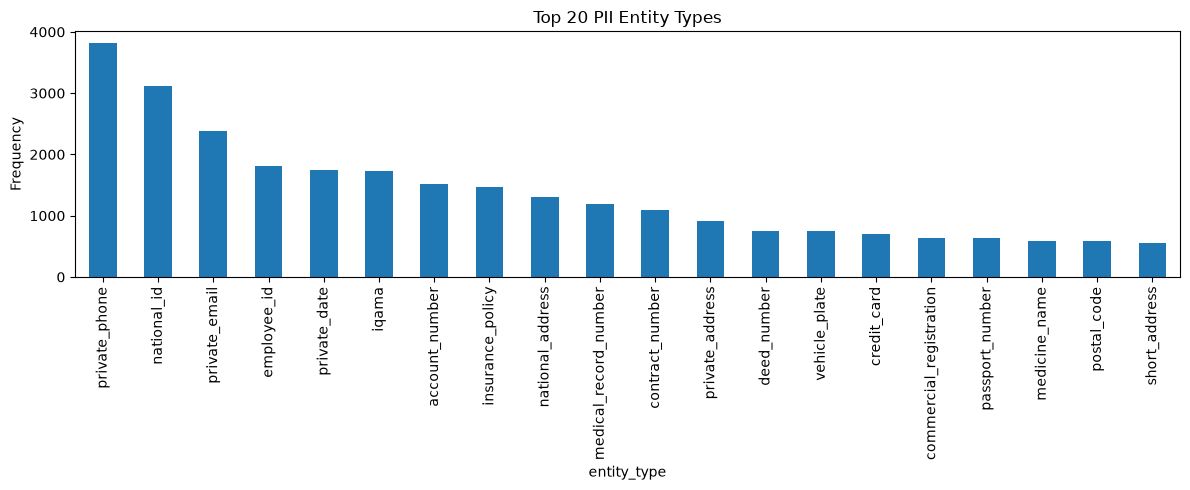

In [11]:
from collections import Counter

entity_counts = Counter(
    entity["label"]
    for entities in df["entities"]
    for entity in entities
)

entity_df = pd.DataFrame(
    entity_counts.items(), 
    columns=["entity_type", "count"]
).sort_values("count", ascending=False)

display(entity_df.head(20))

entity_df.head(20).plot.bar(
    x="entity_type",
    y="count",
    legend=False,
    figsize=(12, 5),
)

plt.title("Top 20 PII Entity Types")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [12]:
print("Total number of unique entity types:", len(entity_df))

display(entity_df.tail(15))

Total number of unique entity types: 43


,entity_type,count
30,syria_phone,240
39,access_token,239
20,spoken_phone,227
24,db_connection,226
19,spoken_iqama,162
37,spoken_national_id,160
36,spoken_otp,147
33,card_cvv,141
29,kuwait_civil_id,130
41,card_pin,125


In [13]:
entity_df['percentage'] = entity_df['count'] / entity_df['count'].sum() * 100

display(entity_df)

,entity_type,count,percentage
4,private_phone,3818,11.724604
18,national_id,3123,9.590345
26,private_email,2385,7.324039
6,employee_id,1819,5.585923
2,private_date,1753,5.383245
12,iqama,1723,5.291119
16,account_number,1509,4.633952
1,insurance_policy,1464,4.495762
13,national_address,1299,3.989068
34,medical_record_number,1191,3.657413


In [14]:
from collections import Counter

document_counts = Counter()

for entities in df["entities"]:
    labels_in_text = {entity["label"] for entity in entities} #we used sets with {} to store unique entity types in each text
    document_counts.update(labels_in_text)

document_df = pd.DataFrame(
    document_counts.items(), # returns a list of tuples (entity_type, document_count) thats why we created two columns in the next line
    columns=["entity_type", "document_count"]
)

comparison_df = entity_df.merge(# merges the two dataframes when entity type matches in both dataframes
    document_df,
    on="entity_type",
)

display(comparison_df)

,entity_type,count,percentage,document_count
0,private_phone,3818,11.724604,2509
1,national_id,3123,9.590345,2175
2,private_email,2385,7.324039,1464
3,employee_id,1819,5.585923,879
4,private_date,1753,5.383245,1371
5,iqama,1723,5.291119,1187
6,account_number,1509,4.633952,986
7,insurance_policy,1464,4.495762,1138
8,national_address,1299,3.989068,957
9,medical_record_number,1191,3.657413,771


## Entity Frequency and Document Frequency - Findings

The dataset contains 43 annotated entity types, with a noticeable imbalance in their frequency.

The most frequent categories are private_phone (3,818 occurrences), national_id (3,123), and private_email (2,385).

The dataset includes both structured identifiers, such as phone numbers and national IDs, and more context-dependent entity types.

Some entity types appear multiple times within the same document. For example, employee_id occurs 1,819 times across 879 documents, suggesting that certain texts contain lists or multiple identifiers.

In contrast, categories such as gulf_iban and otp_code have equal occurrence and document counts, indicating one annotated entity of that type per containing document.

Technical secrets, including api_key, access_token, and db_connection, are represented but have relatively few examples compared with common personal identifiers.